# California Home Price Prediction
## Week 5: Model Comparison

This notebook compares Linear Regression, Decision Tree, and Random Forest. It also checks whether a broader set of raw property features improves prediction.

In [1]:
from pathlib import Path
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.3f}".format

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
RAW_DIR = PROJECT_ROOT / "data" / "raw" / "California"
RANDOM_STATE = 42

## 1. Load and clean the data

Load the same 15 months and keep residential single-family homes. `ListPrice` is used only to identify clear target errors; it is not a prediction feature.

In [2]:
core_numeric = [
    "LivingArea", "BedroomsTotal", "BathroomsTotalInteger",
    "LotSizeSquareFeet", "YearBuilt"
]
core_categorical = ["City", "CountyOrParish"]
extra_numeric = ["Latitude", "Longitude", "GarageSpaces", "ParkingTotal"]
extra_categorical = [
    "PostalCode", "PoolPrivateYN", "ViewYN",
    "NewConstructionYN", "AttachedGarageYN"
]

columns = [
    "ListingKey", "CloseDate", "ClosePrice", "ListPrice",
    "PropertyType", "PropertySubType",
    *core_numeric, *core_categorical, *extra_numeric, *extra_categorical,
]

frames = []
for path in sorted(RAW_DIR.glob("CRMLSSold*.csv")):
    monthly = pd.read_csv(path, usecols=columns, low_memory=False)
    monthly["SourceMonth"] = int(path.stem[-6:])
    frames.append(monthly)

assert len(frames) == 15, f"Expected 15 monthly files, found {len(frames)}"
raw_df = pd.concat(frames, ignore_index=True)
df = raw_df[
    raw_df["PropertyType"].eq("Residential")
    & raw_df["PropertySubType"].eq("SingleFamilyResidence")
].copy()

numeric_columns = ["ClosePrice", "ListPrice", *core_numeric, *extra_numeric]
for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")
df["CloseDate"] = pd.to_datetime(df["CloseDate"], errors="coerce")

close_to_list = df["ClosePrice"] / df["ListPrice"]
bad_target = (
    df["ClosePrice"].isna()
    | (df["ClosePrice"] < 10_000)
    | ((df["ListPrice"] > 0) & ~close_to_list.between(0.2, 5))
)

df = df.loc[~bad_target].copy()
df = df.sort_values(["CloseDate", "SourceMonth"]).drop_duplicates("ListingKey", keep="last")

print(f"Raw rows: {len(raw_df):,}")
print(f"Clear target errors removed: {bad_target.sum():,}")
print(f"Usable single-family sales: {len(df):,}")

Raw rows: 321,972
Clear target errors removed: 115
Usable single-family sales: 161,082


## 2. Prepare features and time periods

The core set contains the seven features used before. The expanded set adds raw location and property details that can be known without using the sale price.

In [3]:
invalid_rules = {
    "LivingArea": df["LivingArea"] <= 0,
    "BedroomsTotal": df["BedroomsTotal"] < 0,
    "BathroomsTotalInteger": df["BathroomsTotalInteger"] < 0,
    "LotSizeSquareFeet": df["LotSizeSquareFeet"] <= 0,
    "YearBuilt": (df["YearBuilt"] < 1800) | (df["YearBuilt"] > df["CloseDate"].dt.year),
    "Latitude": ~df["Latitude"].between(32, 42),
    "Longitude": ~df["Longitude"].between(-125, -114),
    "GarageSpaces": df["GarageSpaces"] < 0,
    "ParkingTotal": df["ParkingTotal"] < 0,
}
for column, mask in invalid_rules.items():
    df.loc[mask.fillna(False), column] = np.nan

all_categorical = core_categorical + extra_categorical
for column in all_categorical:
    values = df[column].astype("string")
    df[column] = values.astype(object).where(values.notna(), np.nan)

core_features = core_numeric + core_categorical
expanded_numeric = core_numeric + extra_numeric
expanded_categorical = core_categorical + extra_categorical
expanded_features = expanded_numeric + expanded_categorical
target = "ClosePrice"

development_train = df[df["SourceMonth"].between(202504, 202602)].copy()
validation = df[df["SourceMonth"] == 202603].copy()
final_train = df[df["SourceMonth"].between(202504, 202603)].copy()
test = df[df["SourceMonth"] == 202604].copy()

assert set(development_train["ListingKey"]).isdisjoint(set(validation["ListingKey"]))
assert set(final_train["ListingKey"]).isdisjoint(set(test["ListingKey"]))
assert development_train["SourceMonth"].max() < validation["SourceMonth"].min()
assert validation["SourceMonth"].max() < test["SourceMonth"].min()

display(pd.DataFrame({
    "purpose": ["Development train", "Validation", "Final train", "Final test"],
    "period": ["2025-04 to 2026-02", "2026-03", "2025-04 to 2026-03", "2026-04"],
    "rows": [len(development_train), len(validation), len(final_train), len(test)],
}))

,purpose,period,rows
0,Development train,2025-04 to 2026-02,118454
1,Validation,2026-03,11165
2,Final train,2025-04 to 2026-03,129619
3,Final test,2026-04,12024


## 3. Build the preprocessing pipeline

- Numeric: median imputation plus missing-value indicators.
- Categorical: `Unknown` imputation and one-hot encoding.
- Linear Regression: numeric scaling.
- Tree models: no scaling because it does not change tree splits.

Rare categories are grouped to keep the encoded data manageable. Every transformer is fitted on training data only.

In [4]:
def make_preprocessor(numeric_features, categorical_features, scale_numeric=False):
    numeric_steps = [
        ("imputer", SimpleImputer(strategy="median", add_indicator=True))
    ]
    if scale_numeric:
        numeric_steps.append(("scaler", StandardScaler()))

    return ColumnTransformer([
        ("numeric", Pipeline(numeric_steps), numeric_features),
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
            ("onehot", OneHotEncoder(
                handle_unknown="infrequent_if_exist", min_frequency=10
            )),
        ]), categorical_features),
    ])

## 4. Compare core and expanded features

Use the same Random Forest and March validation month for both feature sets. This checks whether the added raw features help before final model comparison.

In [5]:
feature_sets = {
    "Core features": (core_numeric, core_categorical),
    "Expanded features": (expanded_numeric, expanded_categorical),
}

feature_results = []
for name, (numeric_set, categorical_set) in feature_sets.items():
    selected_features = numeric_set + categorical_set
    candidate = Pipeline([
        ("preprocessor", make_preprocessor(numeric_set, categorical_set)),
        ("model", RandomForestRegressor(
            n_estimators=40, min_samples_leaf=3, max_features=0.7,
            n_jobs=-1, random_state=RANDOM_STATE
        )),
    ])
    candidate.fit(development_train[selected_features], development_train[target])
    predicted = candidate.predict(validation[selected_features])
    feature_results.append({
        "feature_set": name,
        "number_of_raw_features": len(selected_features),
        "validation_r2": r2_score(validation[target], predicted),
        "validation_mae": mean_absolute_error(validation[target], predicted),
    })

feature_results = pd.DataFrame(feature_results)
display(feature_results)
print("Selected feature set: Expanded features")

,feature_set,number_of_raw_features,validation_r2,validation_mae
0,Core features,7,0.744,"256,059.414"
1,Expanded features,16,0.802,"196,019.217"


Selected feature set: Expanded features


## 5. Select tree settings

Use the expanded features and March validation to compare a small number of settings. April remains untouched.

In [6]:
tree_preprocessor = make_preprocessor(expanded_numeric, expanded_categorical)
X_development = tree_preprocessor.fit_transform(development_train[expanded_features])
X_validation = tree_preprocessor.transform(validation[expanded_features])
y_development = development_train[target]
y_validation = validation[target]

tree_candidates = [
    ("Decision Tree", {"max_depth": 14, "min_samples_leaf": 10}),
    ("Decision Tree", {"max_depth": 20, "min_samples_leaf": 5}),
    ("Decision Tree", {"max_depth": None, "min_samples_leaf": 5}),
]
forest_candidates = [
    ("Random Forest", {"max_depth": 20, "min_samples_leaf": 5}),
    ("Random Forest", {"max_depth": 22, "min_samples_leaf": 3}),
    ("Random Forest", {"max_depth": None, "min_samples_leaf": 3}),
]

validation_rows = []
for name, params in tree_candidates:
    model = DecisionTreeRegressor(random_state=RANDOM_STATE, **params)
    model.fit(X_development, y_development)
    predicted = model.predict(X_validation)
    validation_rows.append({"model": name, **params,
                            "validation_r2": r2_score(y_validation, predicted)})

for name, params in forest_candidates:
    model = RandomForestRegressor(
        n_estimators=50, max_features=0.7, n_jobs=-1,
        random_state=RANDOM_STATE, **params
    )
    model.fit(X_development, y_development)
    predicted = model.predict(X_validation)
    validation_rows.append({"model": name, **params,
                            "validation_r2": r2_score(y_validation, predicted)})

validation_results = pd.DataFrame(validation_rows)
def setting_label(row):
    depth = "None" if pd.isna(row["max_depth"]) else str(int(row["max_depth"]))
    return f"depth={depth}, leaf={int(row['min_samples_leaf'])}"

validation_results["settings"] = validation_results.apply(setting_label, axis=1)
display(validation_results[["model", "settings", "validation_r2"]])

best_dt = (validation_results[validation_results["model"] == "Decision Tree"]
           .sort_values("validation_r2", ascending=False).iloc[0])
best_rf = (validation_results[validation_results["model"] == "Random Forest"]
           .sort_values("validation_r2", ascending=False).iloc[0])

,model,settings,validation_r2
0,Decision Tree,"depth=14.0, leaf=10",0.689
1,Decision Tree,"depth=20.0, leaf=5",0.793
2,Decision Tree,"depth=None, leaf=5",0.796
3,Random Forest,"depth=20.0, leaf=5",0.773
4,Random Forest,"depth=22.0, leaf=3",0.794
5,Random Forest,"depth=None, leaf=3",0.799


## 6. Refit and compare on April 2026

Refit each model on the full 12-month training period, then evaluate once on the final test month.

In [7]:
def selected_depth(value):
    return None if pd.isna(value) else int(value)

models = {
    "Linear Regression": Pipeline([
        ("preprocessor", make_preprocessor(
            expanded_numeric, expanded_categorical, scale_numeric=True
        )),
        ("model", LinearRegression()),
    ]),
    "Decision Tree": Pipeline([
        ("preprocessor", make_preprocessor(expanded_numeric, expanded_categorical)),
        ("model", DecisionTreeRegressor(
            max_depth=selected_depth(best_dt["max_depth"]),
            min_samples_leaf=int(best_dt["min_samples_leaf"]),
            random_state=RANDOM_STATE,
        )),
    ]),
    "Random Forest": Pipeline([
        ("preprocessor", make_preprocessor(expanded_numeric, expanded_categorical)),
        ("model", RandomForestRegressor(
            n_estimators=100,
            max_depth=selected_depth(best_rf["max_depth"]),
            min_samples_leaf=int(best_rf["min_samples_leaf"]),
            max_features=0.7, n_jobs=-1, random_state=RANDOM_STATE,
        )),
    ]),
}

results = []
predictions = {}
for name, model in models.items():
    start = time.perf_counter()
    model.fit(final_train[expanded_features], final_train[target])
    predicted = model.predict(test[expanded_features])
    predictions[name] = predicted
    results.append({
        "model": name,
        "test_r2": r2_score(test[target], predicted),
        "test_mae": mean_absolute_error(test[target], predicted),
        "test_rmse": mean_squared_error(test[target], predicted) ** 0.5,
        "fit_seconds": time.perf_counter() - start,
    })

results = pd.DataFrame(results).sort_values("test_r2", ascending=False).reset_index(drop=True)
display(results)

,model,test_r2,test_mae,test_rmse,fit_seconds
0,Random Forest,0.762,"207,343.446","770,531.080",136.290
1,Linear Regression,0.654,"365,775.245","928,032.798",6.998
2,Decision Tree,0.589,"268,532.665","1,012,132.624",15.935


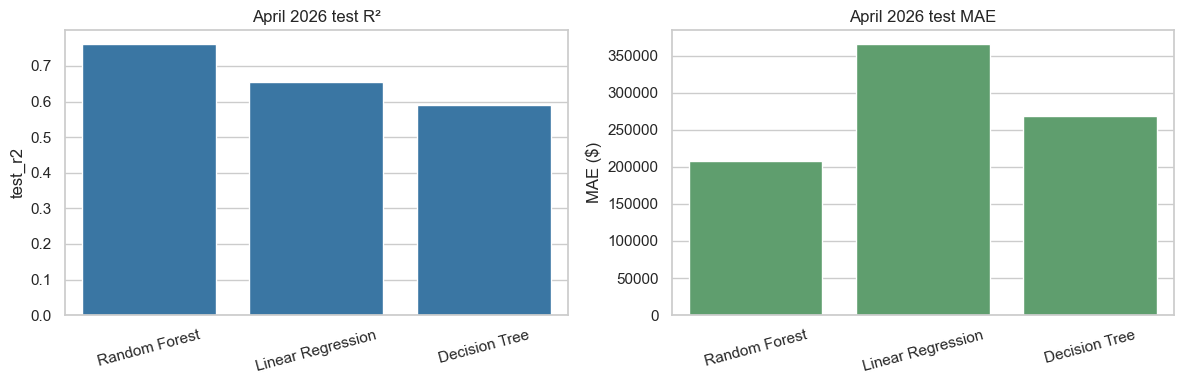

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=results, x="model", y="test_r2", color="#2878B5", ax=axes[0])
axes[0].set_title("April 2026 test R²")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=15)
sns.barplot(data=results, x="model", y="test_mae", color="#55A868", ax=axes[1])
axes[1].set_title("April 2026 test MAE")
axes[1].set_xlabel("")
axes[1].set_ylabel("MAE ($)")
axes[1].tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

## 7. Review the best model

The plot is limited to the first 99% of test prices for readability. Reported metrics still use every test row.

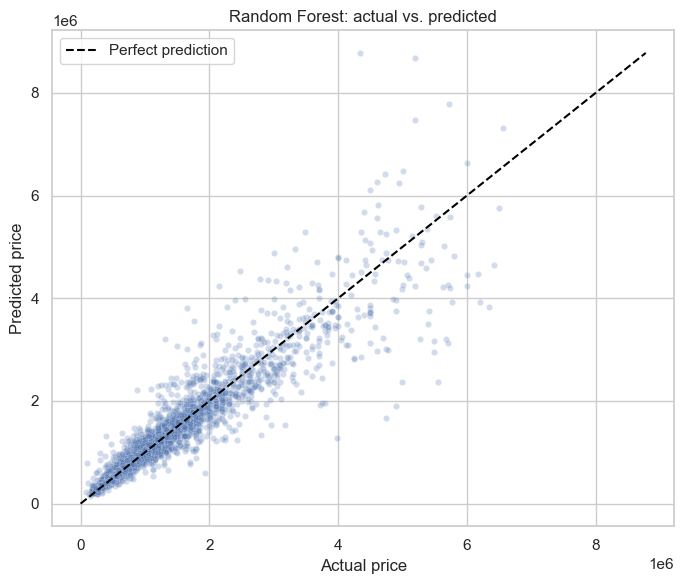

In [9]:
best_name = results.loc[0, "model"]
best_predictions = predictions[best_name]
plot_data = pd.DataFrame({
    "Actual price": test[target].to_numpy(),
    "Predicted price": best_predictions,
})
plot_data = plot_data[plot_data["Actual price"] <= test[target].quantile(0.99)]
plot_data = plot_data.sample(min(4000, len(plot_data)), random_state=RANDOM_STATE)

plt.figure(figsize=(7, 6))
sns.scatterplot(data=plot_data, x="Actual price", y="Predicted price", alpha=0.25, s=20)
line_max = plot_data[["Actual price", "Predicted price"]].max().max()
plt.plot([0, line_max], [0, line_max], "--", color="black", label="Perfect prediction")
plt.title(f"{best_name}: actual vs. predicted")
plt.legend()
plt.tight_layout()
plt.show()

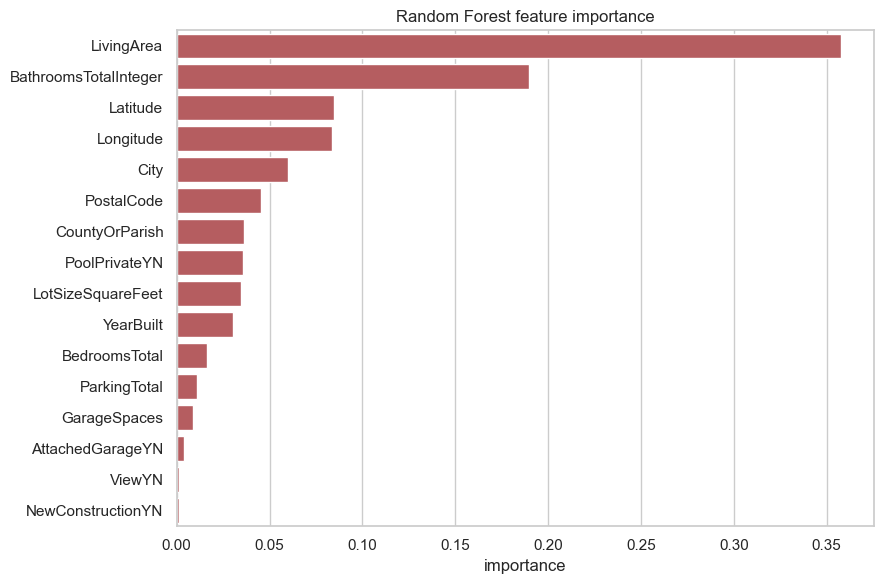

,feature,importance
7,LivingArea,0.358
1,BathroomsTotalInteger,0.190
6,Latitude,0.085
8,Longitude,0.083
3,City,0.060
13,PostalCode,0.045
4,CountyOrParish,0.036
12,PoolPrivateYN,0.036
9,LotSizeSquareFeet,0.035
15,YearBuilt,0.030


In [10]:
forest = models["Random Forest"]
encoded_names = forest.named_steps["preprocessor"].get_feature_names_out()
encoded_importance = pd.DataFrame({
    "encoded_feature": encoded_names,
    "importance": forest.named_steps["model"].feature_importances_,
})

def original_feature(encoded_name):
    for feature in expanded_features:
        if feature in encoded_name:
            return feature
    return encoded_name

encoded_importance["feature"] = encoded_importance["encoded_feature"].map(original_feature)
importance = (encoded_importance.groupby("feature", as_index=False)["importance"]
              .sum().sort_values("importance", ascending=False))

plt.figure(figsize=(9, 6))
sns.barplot(data=importance, x="importance", y="feature", color="#C44E52")
plt.title("Random Forest feature importance")
plt.ylabel("")
plt.tight_layout()
plt.show()
display(importance)

## Conclusion

- Expanded raw features improved March validation performance compared with the core feature set.
- Every model used the same expanded features and April 2026 test set.
- Random Forest produced the best final result.
- Linear Regression is fast and interpretable but cannot capture all nonlinear relationships.
- A single Decision Tree is easy to explain but less stable.
- Random Forest is more accurate and stable, but slower and less interpretable.

Week 6 can build on this result with engineered features such as property age, ratios, and school-district geography.